In [7]:
# ==========================================
# BLOQUE 1: Importar librerías y cargar datos reales del SENAMHI
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("crest")

file_path = "/content/Variables Meteorologicas de las Estaciones automáticas de intercambio internacional - [Servicio Nacional de Meteorología e Hidrología del Perú - SENAMHI]_0.csv"
df = pd.read_csv(file_path, encoding="latin1")

print("Filas y columnas:", df.shape)
print("\nColumnas disponibles:\n", df.columns)
df.head()


Filas y columnas: (236797, 16)

Columnas disponibles:
 Index(['ID', 'ESTACION', 'FECHA', 'HORA', 'LONGITUD', 'LATITUD', 'ALTITUD',
       'TEMP', 'HR', 'PP', 'RED', 'DEPARTAMENTO', 'PROVINCIA', 'DISTRITO',
       'UBIGEO', 'FECHA_CORTE'],
      dtype='object')


,ID,ESTACION,FECHA,HORA,LONGITUD,LATITUD,ALTITUD,TEMP,HR,PP,RED,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,FECHA_CORTE
0,1,CANDARAVE,20150101,0,-70.2541,-17.268,3410.0,6.6,73.0,0.0,RBON,TACNA,CANDARAVE,CANDARAVE,230201.0,20240630.0
1,2,CANDARAVE,20150101,10000,-70.2541,-17.268,3410.0,6.1,66.0,0.0,RBON,TACNA,CANDARAVE,CANDARAVE,230201.0,20240630.0
2,3,CANDARAVE,20150101,20000,-70.2541,-17.268,3410.0,5.2,63.0,0.0,RBON,TACNA,CANDARAVE,CANDARAVE,230201.0,20240630.0
3,4,CANDARAVE,20150101,30000,-70.2541,-17.268,3410.0,5.1,49.0,0.0,RBON,TACNA,CANDARAVE,CANDARAVE,230201.0,20240630.0
4,5,CANDARAVE,20150101,40000,-70.2541,-17.268,3410.0,3.8,51.0,0.0,RBON,TACNA,CANDARAVE,CANDARAVE,230201.0,20240630.0


In [8]:
# ==========================================
# BLOQUE 2: Limpieza, timestamp y filtros
# ==========================================
import pandas as pd
import numpy as np

df_raw = df.copy()

df_raw.columns = [c.strip().upper() for c in df_raw.columns]


df_raw['FECHA'] = pd.to_datetime(df_raw['FECHA'].astype(str), format='%Y%m%d', errors='coerce')

hora_str = df_raw['HORA'].astype(str).str.zfill(6)
df_raw['HORA_TD'] = pd.to_timedelta(hora_str.str[0:2] + ':' + hora_str.str[2:4] + ':' + hora_str.str[4:6])

df_raw['TS'] = df_raw['FECHA'] + df_raw['HORA_TD']

for col in ['LONGITUD','LATITUD','ALTITUD','TEMP','HR','PP']:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')

df_raw = df_raw.dropna(subset=['TS','TEMP'])

df_raw['ANIO']   = df_raw['TS'].dt.year
df_raw['MES']    = df_raw['TS'].dt.month
df_raw['DIA']    = df_raw['TS'].dt.day
df_raw['HORA24'] = df_raw['TS'].dt.hour
df_raw['DOW']    = df_raw['TS'].dt.dayofweek

df_geo = df_raw.copy()
df_geo = df_geo[df_geo['DEPARTAMENTO'].str.upper().eq('LIMA')]



print("Registros tras limpieza+filtro:", df_geo.shape)
df_geo.head(3)


Registros tras limpieza+filtro: (81667, 23)


,ID,ESTACION,FECHA,HORA,LONGITUD,LATITUD,ALTITUD,TEMP,HR,PP,...,DISTRITO,UBIGEO,FECHA_CORTE,HORA_TD,TS,ANIO,MES,DIA,HORA24,DOW
83256,83257,CARANIA,2015-01-01,0,-75.8722,-12.3444,3840.0,4.6,100.0,0.1,...,CARANIA,151007.0,20240630.0,0 days 00:00:00,2015-01-01 00:00:00,2015,1,1,0,3
83257,83258,CARANIA,2015-01-01,10000,-75.8722,-12.3444,3840.0,4.7,100.0,0.0,...,CARANIA,151007.0,20240630.0,0 days 01:00:00,2015-01-01 01:00:00,2015,1,1,1,3
83258,83259,CARANIA,2015-01-01,20000,-75.8722,-12.3444,3840.0,5.1,100.0,0.0,...,CARANIA,151007.0,20240630.0,0 days 02:00:00,2015-01-01 02:00:00,2015,1,1,2,3


In [9]:
# ==========================================
# BLOQUE 3: Selección de X/y y train/test
# ==========================================
from sklearn.model_selection import train_test_split

TARGET = 'TEMP'

feat_num  = ['LATITUD','LONGITUD','ALTITUD','HORA24','MES','DOW']
feat_cat  = ['DISTRITO','PROVINCIA','RED']
feat_all  = feat_num + feat_cat

df_model = df_geo.dropna(subset=[TARGET] + feat_num)

X = pd.get_dummies(df_model[feat_all], columns=feat_cat, drop_first=True)
y = df_model[TARGET].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

X_train.shape, X_test.shape


((65333, 6), (16334, 6))

In [10]:
# ==========================================
# BLOQUE 4’: Instalar skranger y crear QRF robusto a la versión
# ==========================================
!pip -q install skranger

from skranger.ensemble import RangerForestRegressor
from inspect import signature

init_params = set(signature(RangerForestRegressor.__init__).parameters.keys())
init_params

kwargs = {}
if 'num_trees' in init_params:
    kwargs['num_trees'] = 500
elif 'n_estimators' in init_params:
    kwargs['n_estimators'] = 500

if 'min_node_size' in init_params:
    kwargs['min_node_size'] = 200
elif 'min_samples_leaf' in init_params:
    kwargs['min_samples_leaf'] = 200

if 'quantiles' in init_params:
    kwargs['quantiles'] = True
elif 'prediction_type' in init_params:
    kwargs['prediction_type'] = 'quantiles'

for k, v in [('mtry', None), ('sample_fraction', 1.0), ('random_state', 42)]:
    if k in init_params and v is not None:
        kwargs[k] = v

qrf = RangerForestRegressor(**kwargs)
qrf


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.5/116.5 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


RangerForestRegressor(min_node_size=200, n_estimators=500, quantiles=True,
                      sample_fraction=1.0)

Cobertura: 0.782 | Ancho medio: 4.103 TEMP
fuera_intervalo
False    12773
True      3561
Name: count, dtype: int64


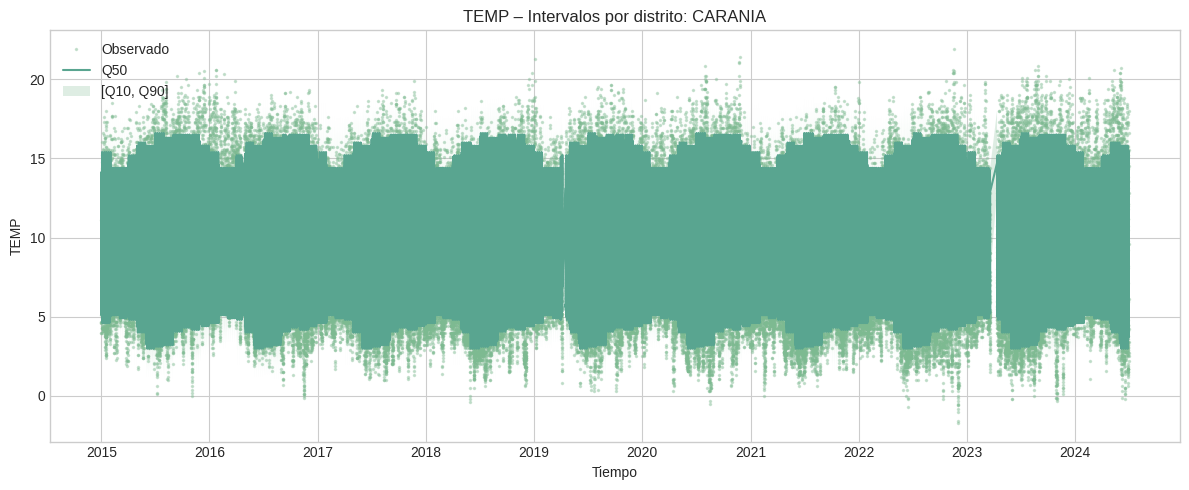

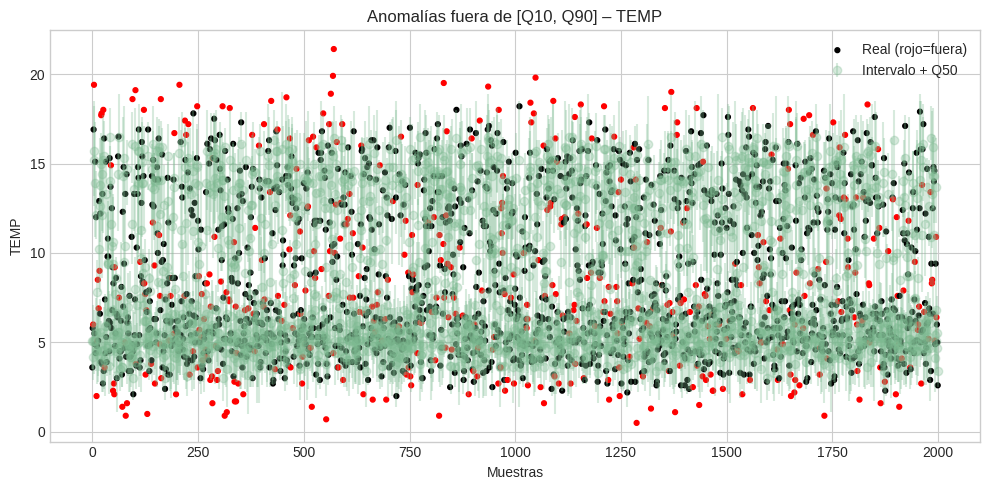

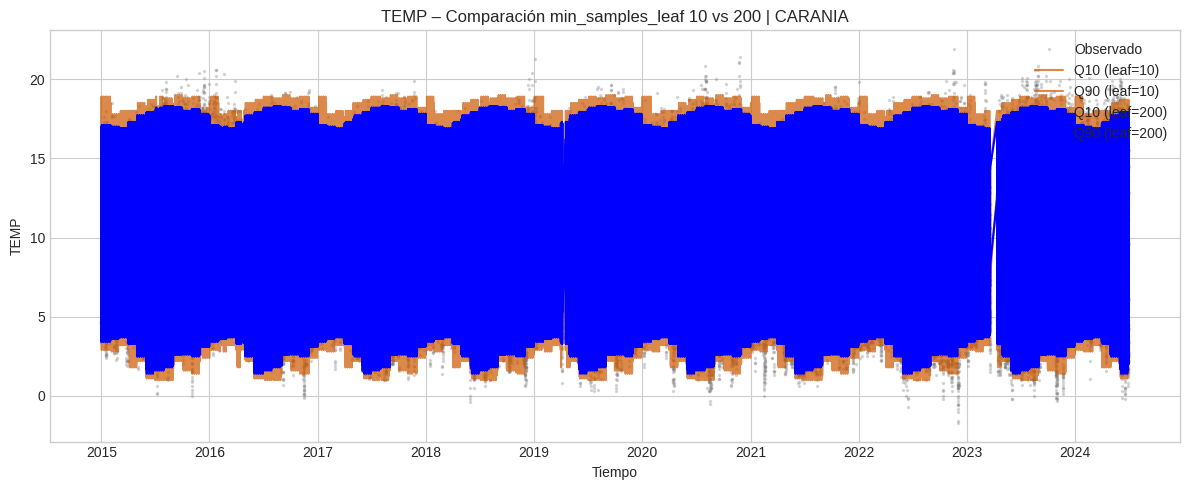

In [12]:
# =========================
# QRF ESTABLE (quantile-forest) + INTERVALOS + ANOMALÍAS + COMPARACIÓN
# =========================
!pip -q install quantile-forest

import numpy as np
import matplotlib.pyplot as plt
from quantile_forest import RandomForestQuantileRegressor

qrf = RandomForestQuantileRegressor(
    n_estimators=500,
    random_state=42,
    min_samples_leaf=5,
    n_jobs=-1
)
qrf.fit(X_train, y_train)

q_lower, q_med, q_upper = 0.10, 0.50, 0.90
pred_q = qrf.predict(X_test, quantiles=[q_lower, q_med, q_upper])
y_q10, y_q50, y_q90 = pred_q[:,0], pred_q[:,1], pred_q[:,2]

coverage = np.mean((y_test.values >= y_q10) & (y_test.values <= y_q90))
width    = np.mean(y_q90 - y_q10)
print(f"Cobertura: {coverage:.3f} | Ancho medio: {width:.3f} {TARGET}")

res = pd.DataFrame({
    'y_real': y_test.values,
    'q10': y_q10,
    'q50': y_q50,
    'q90': y_q90
}, index=y_test.index)
res['fuera_intervalo'] = (res['y_real'] < res['q10']) | (res['y_real'] > res['q90'])
print(res['fuera_intervalo'].value_counts())

top_dist = df_geo['DISTRITO'].value_counts().index[0]
df_dist = df_geo[df_geo['DISTRITO'] == top_dist].copy().sort_values('TS')
X_dist = pd.get_dummies(df_dist[feat_all], columns=['DISTRITO','PROVINCIA','RED'], drop_first=True)\
          .reindex(columns=X.columns, fill_value=0)

pred_q_dist = qrf.predict(X_dist, quantiles=[q_lower, q_med, q_upper])
q10_d, q50_d, q90_d = pred_q_dist[:,0], pred_q_dist[:,1], pred_q_dist[:,2]

plt.figure(figsize=(12,5))
plt.plot(df_dist['TS'], df_dist[TARGET], '.', ms=3, alpha=0.35, label='Observado')
plt.plot(df_dist['TS'], q50_d, lw=1.5, label='Q50')
plt.fill_between(df_dist['TS'], q10_d, q90_d, alpha=0.25, label='[Q10, Q90]')
plt.title(f'{TARGET} – Intervalos por distrito: {top_dist}')
plt.xlabel('Tiempo'); plt.ylabel(TARGET); plt.legend(); plt.tight_layout(); plt.show()

n = min(2000, len(res))
sample_idx = res.sample(n, random_state=42).index
x_axis = np.arange(len(sample_idx))

plt.figure(figsize=(10,5))
plt.errorbar(
    x_axis, res.loc[sample_idx,'q50'],
    yerr=[res.loc[sample_idx,'q50']-res.loc[sample_idx,'q10'],
          res.loc[sample_idx,'q90']-res.loc[sample_idx,'q50']],
    fmt='o', alpha=0.3, label='Intervalo + Q50'
)
plt.scatter(
    x_axis, res.loc[sample_idx,'y_real'], s=12,
    c=np.where(res.loc[sample_idx,'fuera_intervalo'], 'red', 'black'),
    label='Real (rojo=fuera)'
)
plt.title(f'Anomalías fuera de [Q10, Q90] – {TARGET}')
plt.xlabel('Muestras'); plt.ylabel(TARGET); plt.legend(); plt.tight_layout(); plt.show()

qrf_10  = RandomForestQuantileRegressor(n_estimators=500, random_state=42, min_samples_leaf=10,  n_jobs=-1).fit(X_train, y_train)
qrf_200 = RandomForestQuantileRegressor(n_estimators=500, random_state=42, min_samples_leaf=200, n_jobs=-1).fit(X_train, y_train)

pred_10  = qrf_10.predict (X_dist, quantiles=[0.10, 0.90])
pred_200 = qrf_200.predict(X_dist, quantiles=[0.10, 0.90])

plt.figure(figsize=(12,5))
plt.plot(df_dist['TS'], df_dist[TARGET], '.', ms=3, alpha=0.25, color='gray', label='Observado')
plt.plot(df_dist['TS'], pred_10[:,0],  color='#cd5700', alpha=0.7, label='Q10 (leaf=10)')
plt.plot(df_dist['TS'], pred_10[:,1],  color='#cd5700', alpha=0.7, label='Q90 (leaf=10)')
plt.plot(df_dist['TS'], pred_200[:,0], color='blue',    label='Q10 (leaf=200)')
plt.plot(df_dist['TS'], pred_200[:,1], color='blue',    label='Q90 (leaf=200)')
plt.title(f'{TARGET} – Comparación min_samples_leaf 10 vs 200 | {top_dist}')
plt.xlabel('Tiempo'); plt.ylabel(TARGET); plt.legend(loc='upper right'); plt.tight_layout(); plt.show()


In [13]:
# ==========================================
# ANOMALÍAS POR MES (
# ==========================================
import pandas as pd
import numpy as np
import plotly.express as px

tmp = df_geo.loc[res.index, ['TS','DISTRITO']].copy()
tmp['anomalia'] = res['fuera_intervalo'].astype(int)

tmp['ym'] = tmp['TS'].dt.to_period('M').dt.to_timestamp()
agg = tmp.groupby('ym').agg(
    total=('anomalia','size'),
    anoms=('anomalia','sum')
).reset_index()
agg['rate'] = (agg['anoms'] / agg['total']).astype(float)

neon = ['#00F5FF','#39FF14','#FF10F0','#FCEE0C','#FF6EC7','#00FF7F','#00BFFF']

fig_rate = px.line(
    agg, x='ym', y='rate',
    title=f'Tasa mensual de anomalías – {TARGET}',
    markers=True, color_discrete_sequence=[neon[2]]
)
fig_rate.update_layout(template='plotly_dark', hovermode='x unified',
                       xaxis_title='Mes', yaxis_title='Tasa (fuera de [Q10,Q90])',
                       plot_bgcolor='#000', paper_bgcolor='#000')
fig_rate.update_traces(line=dict(width=3))
fig_rate.show()

fig_cnt = px.bar(
    agg, x='ym', y='anoms',
    title=f'Conteo mensual de anomalías – {TARGET}',
    color='anoms', color_continuous_scale=neon,
)
fig_cnt.update_layout(template='plotly_dark', hovermode='x unified',
                      xaxis_title='Mes', yaxis_title='# Anomalías',
                      plot_bgcolor='#000', paper_bgcolor='#000')
fig_cnt.show()


In [14]:
import os, requests, geopandas as gpd

url_geojson = "https://raw.githubusercontent.com/joseluisq/peru-geojson-datasets/master/lima_callao_distritos_simple.geojson"
path_geojson = "/content/lima_distritos.geojson"

if not os.path.exists(path_geojson):
    r = requests.get(url_geojson, timeout=60)
    r.raise_for_status()
    with open(path_geojson, "wb") as f:
        f.write(r.content)

gdf = gpd.read_file(path_geojson)

def _norm(s):
    return (s.str.upper()
            .str.normalize('NFKD')
            .str.replace(r'[^A-Z\s]', '', regex=True)
            .str.strip())

if 'DISTRITO' in gdf.columns:
    gdf['DIST_NORM'] = _norm(gdf['DISTRITO'].astype(str))
elif 'distrito' in gdf.columns:
    gdf['DIST_NORM'] = _norm(gdf['distrito'].astype(str))
else:
    raise ValueError("No encuentro columna de distrito en el GeoJSON.")

df_geo['_DIST_NORM_'] = _norm(df_geo['DISTRITO'].astype(str))
test_distritos = df_geo.loc[res.index, '_DIST_NORM_']

anom_df = pd.DataFrame({
    'DIST_NORM': test_distritos.values,
    'fuera_intervalo': res['fuera_intervalo'].values.astype(int)
})
grp = anom_df.groupby('DIST_NORM').agg(
    anoms=('fuera_intervalo','sum'),
    total=('fuera_intervalo','size')
).reset_index()
grp['rate'] = (grp['anoms'] / grp['total']).astype(float)

map_df = gdf.merge(grp, on='DIST_NORM', how='left').fillna({'anoms':0,'total':0,'rate':0})


In [15]:
import plotly.express as px

neon_seq = ['#000004','#280B53','#5800FF','#00BFFF','#39FF14','#FCEE0C','#FF10F0']

# 1) Mapa por # de anomalías
fig_map_cnt = px.choropleth_mapbox(
    map_df,
    geojson=map_df.__geo_interface__,
    locations=map_df.index,
    color='anoms',
    color_continuous_scale=neon_seq,
    mapbox_style='carto-darkmatter',
    zoom=9.2, center={"lat": -12.05, "lon": -77.05},
    opacity=0.88,
    hover_data={'DIST_NORM':True,'anoms':True,'total':True,'rate':':.2f'},
    title=f'Anomalías por distrito – {TARGET}'
)
fig_map_cnt.update_layout(template='plotly_dark', paper_bgcolor='#000', plot_bgcolor='#000',
                          margin=dict(l=0,r=0,t=50,b=0))
fig_map_cnt.show()

# 2) Mapa por tasa de anomalías
fig_map_rate = px.choropleth_mapbox(
    map_df,
    geojson=map_df.__geo_interface__,
    locations=map_df.index,
    color='rate',
    color_continuous_scale=neon_seq,
    range_color=(0, map_df['rate'].max() if map_df['rate'].max()>0 else 0.001),
    mapbox_style='carto-darkmatter',
    zoom=9.2, center={"lat": -12.05, "lon": -77.05},
    opacity=0.88,
    hover_data={'DIST_NORM':True,'anoms':True,'total':True,'rate':':.2f'},
    title=f'Tasa de anomalías por distrito – {TARGET}'
)
fig_map_rate.update_layout(template='plotly_dark', paper_bgcolor='#000', plot_bgcolor='#000',
                           margin=dict(l=0,r=0,t=50,b=0))
fig_map_rate.show()


Delitos Denunciados

In [24]:
from google.colab import files
uploaded = files.upload()

Saving delitos-denunciados-2025-09.csv to delitos-denunciados-2025-09.csv
Saving delitos-denunciados-2023_0.csv to delitos-denunciados-2023_0.csv
Saving delitos-denunciados-2024.csv to delitos-denunciados-2024.csv
Saving delitos denunciados 2021.csv to delitos denunciados 2021.csv
Saving delitos denunciados 2022.csv to delitos denunciados 2022.csv
Saving delitos denunciados 2020.csv to delitos denunciados 2020.csv


In [25]:
!pip -q install skranger pyproj==3.6.1 shapely==2.0.5 geopandas==0.14.4 folium==0.16.0

import os, re, json, unicodedata, glob
import numpy as np
import pandas as pd
import geopandas as gpd
import plotly.express as px
from datetime import datetime
from skranger.ensemble import RangerForestRegressor

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.0/100.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 61.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geemap 0.35.3 requires folium>=0.17.0, but you have folium 0.16.0 which is incompatible.


In [40]:
import os, glob, pandas as pd, re

def read_try_encodings(path, nrows=None):
    encs = ["utf-8-sig", "utf-8", "latin1", "cp1252"]
    last_err = None
    for enc in encs:
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False, nrows=nrows)
        except Exception as e:
            last_err = e
    raise last_err

def pick_col(cols, *cands):
    cols_norm = {c: c.strip().lower() for c in cols}
    inv = {v: k for k, v in cols_norm.items()}
    for c in cands:
        if c in cols_norm.values():
            return inv[c]
    pats = [re.compile(c.replace("_", ".?")) for c in cands]
    for c in cols:
        cn = c.strip().lower()
        if any(p.search(cn) for p in pats):
            return c
    return None

files = sorted(glob.glob("delitos*.csv"))
if not files:
    print("No se encontraron archivos que coincidan con 'delitos*.csv' en el directorio actual.")
else:
    print(f"Encontrados {len(files)} archivos:\n")
    for p in files:
        try:
            df = read_try_encodings(p, nrows=200)
            cols = list(df.columns)
            n_preview = 5

            c_dist = pick_col(cols, "distrito_fiscal", "distrito fiscal", "distrito")
            c_anio = pick_col(cols, "anio_denuncia", "año_denuncia", "anio", "año", "periodo_denuncia", "periodo")
            c_mes  = pick_col(cols, "mes", "mes_denuncia", "periodo_denuncia", "periodo")

            print("="*110)
            print(f"📄 {os.path.basename(p)}")
            print(f"   Filas (preview): {len(df):>5} | Columnas: {len(cols):>2}")
            print(f"   Primeras {n_preview} columnas: {cols[:n_preview]}")
            print(f"   TODAS las columnas:\n   {cols}")
            print("   Sugerencias ↴")
            print(f"     - DISTRITO_FISCAL: {c_dist}")
            print(f"     - ANIO            : {c_anio}")
            print(f"     - MES             : {c_mes}")

            show_cols = [c for c in [c_dist, c_anio, c_mes] if c is not None]
            if show_cols:
                print("   Muestra de valores:")
                print(df[show_cols].head(3).to_string(index=False))
        except Exception as e:
            print("="*110)
            print(f"📄 {os.path.basename(p)}")
            print(f"   ERROR al leer: {e}")



Encontrados 7 archivos:

📄 delitos denunciados 2020.csv
   Filas (preview):   200 | Columnas: 16
   Primeras 5 columnas: ['periodo_denuncia', 'anio_denuncia', 'Fecha_descarga', 'distrito_fiscal', 'especialidad']
   TODAS las columnas:
   ['periodo_denuncia', 'anio_denuncia', 'Fecha_descarga', 'distrito_fiscal', 'especialidad', 'tipo_caso', 'generico', 'subgenerico', 'articulo', 'des_articulo', 'cantidad', 'ubigeo_pjfs', 'dpto_pjfs', 'prov_pjfs', 'dist_pjfs', 'fecha_corte']
   Sugerencias ↴
     - DISTRITO_FISCAL: distrito_fiscal
     - ANIO            : anio_denuncia
     - MES             : periodo_denuncia
   Muestra de valores:
distrito_fiscal  anio_denuncia  periodo_denuncia
       AMAZONAS           2020 ENERO - DICIEMBRE
       AMAZONAS           2020 ENERO - DICIEMBRE
       AMAZONAS           2020 ENERO - DICIEMBRE
📄 delitos denunciados 2021.csv
   Filas (preview):   200 | Columnas: 16
   Primeras 5 columnas: ['periodo_denuncia', 'anio_denuncia', 'Fecha_descarga', 'distrito_fis

In [46]:
import os, re, glob
import pandas as pd
import numpy as np

raw_files = sorted(
    glob.glob("delitos denunciados*.csv") +
    glob.glob("delitos-denunciados*.csv")
)

print("Archivos candidatos:", [os.path.basename(p) for p in raw_files])

def read_mpf_csv(path):
    df = pd.read_csv(path, encoding="utf-8", low_memory=False)
    cols = {c.lower(): c for c in df.columns}
    c_distr = cols.get("distrito_fiscal")
    c_anio  = cols.get("anio_denuncia")
    c_per   = cols.get("periodo_denuncia")
    c_cant  = cols.get("cantidad") if "cantidad" in cols else None

    if not (c_distr and c_anio and c_per):
        miss = [x for x,y in [("distrito_fiscal",c_distr),("anio_denuncia",c_anio),("periodo_denuncia",c_per)] if y is None]
        print(f"SKIP (faltan columnas {miss}): {os.path.basename(path)}")
        return None

    out = pd.DataFrame({
        "DISTRITO_FISCAL": df[c_distr].astype(str).str.strip(),
        "ANIO": pd.to_numeric(df[c_anio], errors="coerce").astype("Int64"),
        "PERIODO": df[c_per].astype(str).str.strip()
    })

    if c_cant:
        out["cantidad"] = pd.to_numeric(df[c_cant], errors="coerce").fillna(0).astype(int)

    out = out[out["ANIO"].notna()]
    out["ANIO"] = out["ANIO"].astype(int)
    return out

dfs = []
for p in raw_files:
    dfi = read_mpf_csv(p)
    if dfi is None or dfi.empty:
        continue
    print(f"OK {os.path.basename(p):<35} -> filas={len(dfi)} | usa_cantidad={('cantidad' in dfi.columns)}")
    dfs.append(dfi)

if not dfs:
    raise AssertionError("No quedó ningún CSV compatible (revisa nombres y columnas).")

raw = pd.concat(dfs, ignore_index=True)
print("RAW shape:", raw.shape)
raw.head()


Archivos candidatos: ['delitos denunciados 2020.csv', 'delitos denunciados 2021.csv', 'delitos denunciados 2022.csv', 'delitos-denunciados-2023_0.csv', 'delitos-denunciados-2024.csv', 'delitos-denunciados-2025-09.csv']
OK delitos denunciados 2020.csv        -> filas=8583 | usa_cantidad=True
OK delitos denunciados 2021.csv        -> filas=12314 | usa_cantidad=True
OK delitos denunciados 2022.csv        -> filas=9152 | usa_cantidad=True
OK delitos-denunciados-2023_0.csv      -> filas=9032 | usa_cantidad=True
OK delitos-denunciados-2024.csv        -> filas=8906 | usa_cantidad=True
OK delitos-denunciados-2025-09.csv     -> filas=8303 | usa_cantidad=True
RAW shape: (56290, 4)


,DISTRITO_FISCAL,ANIO,PERIODO,cantidad
0,AMAZONAS,2020,ENERO - DICIEMBRE,1
1,AMAZONAS,2020,ENERO - DICIEMBRE,1
2,AMAZONAS,2020,ENERO - DICIEMBRE,1
3,AMAZONAS,2020,ENERO - DICIEMBRE,2
4,AMAZONAS,2020,ENERO - DICIEMBRE,1


In [36]:

if "cantidad" in raw.columns:
    df_anual = (raw
        .groupby(["DISTRITO_FISCAL","ANIO"], as_index=False)["cantidad"].sum()
        .rename(columns={"cantidad":"TOTAL_DELITOS"})
    )
else:
    df_anual = (raw
        .groupby(["DISTRITO_FISCAL","ANIO"], as_index=False)
        .size().rename(columns={"size":"TOTAL_DELITOS"})
    )

df_anual = df_anual.sort_values(["ANIO","DISTRITO_FISCAL"]).reset_index(drop=True)

print(df_anual.head(12).to_string(index=False))
print("Shape anual:", df_anual.shape)

df_anual.to_csv("delitos_anual_2020_2025.csv", index=False, encoding="utf-8")
print("✅ Guardado: delitos_anual_2020_2025.csv")


DISTRITO_FISCAL  ANIO  TOTAL_DELITOS
       AMAZONAS  2020           8572
         ANCASH  2020          13762
       APURIMAC  2020          12520
       AREQUIPA  2020          33909
       AYACUCHO  2020          12964
      CAJAMARCA  2020          16299
         CALLAO  2020          19479
         CAÑETE  2020           9130
          CUSCO  2020          31537
   HUANCAVELICA  2020           4650
        HUANUCO  2020          19704
         HUAURA  2020          12656
Shape anual: (204, 3)
✅ Guardado: delitos_anual_2020_2025.csv


In [42]:
import pandas as pd

df_anual = pd.read_csv("delitos_anual_2020_2025.csv", encoding="utf-8")
print(df_anual.head(12).to_string(index=False))
print("Shape anual:", df_anual.shape)

print("\nFilas por ANIO:")
print(df_anual['ANIO'].value_counts().sort_index())

top_2025 = (df_anual[df_anual['ANIO']==2025]
            .sort_values('TOTAL_DELITOS', ascending=False)
            .head(10))
print("\nTop 10  (2025):")
print(top_2025.to_string(index=False))


DISTRITO_FISCAL  ANIO  TOTAL_DELITOS
       AMAZONAS  2020           8572
         ANCASH  2020          13762
       APURIMAC  2020          12520
       AREQUIPA  2020          33909
       AYACUCHO  2020          12964
      CAJAMARCA  2020          16299
         CALLAO  2020          19479
         CAÑETE  2020           9130
          CUSCO  2020          31537
   HUANCAVELICA  2020           4650
        HUANUCO  2020          19704
         HUAURA  2020          12656
Shape anual: (204, 3)

Filas por ANIO:
ANIO
2020    34
2021    34
2022    34
2023    34
2024    34
2025    34
Name: count, dtype: int64

Top 10  (2025):
DISTRITO_FISCAL  ANIO  TOTAL_DELITOS
    LIMA CENTRO  2025          91981
     LIMA NORTE  2025          70034
     LAMBAYEQUE  2025          69868
      LIMA ESTE  2025          65823
       AREQUIPA  2025          56025
       LIMA SUR  2025          48212
    LA LIBERTAD  2025          46754
          JUNIN  2025          37419
          CUSCO  2025          34

In [43]:
pivot = (df_anual
         .pivot_table(index='DISTRITO_FISCAL',
                      columns='ANIO',
                      values='TOTAL_DELITOS',
                      aggfunc='sum')
         .fillna(0)
         .astype(int))

pivot = pivot.reindex(sorted(pivot.columns), axis=1)
pivot.head(15)
pivot.to_csv("delitos_anual_wide_2020_2025.csv", encoding="utf-8")
print("✅ Guardado: delitos_anual_wide_2020_2025.csv")


✅ Guardado: delitos_anual_wide_2020_2025.csv


In [44]:
wide = pivot.copy()

if 2020 in wide.columns and 2025 in wide.columns:
    wide['var_2025_vs_2020_%'] = ((wide[2025] - wide[2020]) / wide[2020].replace(0, pd.NA)) * 100

for y in range(2021, 2026):
    if y in wide.columns and (y-1) in wide.columns:
        wide[f'YoY_{y}_abs'] = wide[y] - wide[y-1]
        wide[f'YoY_{y}_%'] = ((wide[y] - wide[y-1]) / wide[y-1].replace(0, pd.NA)) * 100

wide.to_csv("delitos_anual_wide_con_métricas.csv", encoding="utf-8")
print("✅ Guardado: delitos_anual_wide_con_métricas.csv")
wide.head(10)


✅ Guardado: delitos_anual_wide_con_métricas.csv


ANIO,2020,2021,2022,2023,2024,2025,var_2025_vs_2020_%,YoY_2021_abs,YoY_2021_%,YoY_2022_abs,YoY_2022_%,YoY_2023_abs,YoY_2023_%,YoY_2024_abs,YoY_2024_%,YoY_2025_abs,YoY_2025_%
DISTRITO_FISCAL,,,,,,,,,,,,,,,,,
AMAZONAS,8572,14035,13787,14956,14905,11131,29.853010,5463,63.730751,-248,-1.767011,1169,8.479002,-51,-0.341000,-3774,-25.320362
ANCASH,13762,18715,19951,21223,22799,17186,24.880105,4953,35.990408,1236,6.604328,1272,6.375620,1576,7.425906,-5613,-24.619501
APURIMAC,12520,16836,12698,17014,18065,13372,6.805112,4316,34.472843,-4138,-24.578285,4316,33.989605,1051,6.177266,-4693,-25.978411
AREQUIPA,33909,67113,66997,74940,74263,56025,65.221623,33204,97.920906,-116,-0.172843,7943,11.855755,-677,-0.903389,-18238,-24.558663
AYACUCHO,12964,25277,25035,28624,30783,20796,60.413453,12313,94.978402,-242,-0.957392,3589,14.335930,2159,7.542622,-9987,-32.443232
CAJAMARCA,16299,23850,24206,27589,27279,18993,16.528621,7551,46.327996,356,1.492662,3383,13.975874,-310,-1.123636,-8286,-30.375014
CALLAO,19479,26417,38045,34009,29530,22088,13.393911,6938,35.617845,11628,44.017110,-4036,-10.608490,-4479,-13.170043,-7442,-25.201490
CAÑETE,9130,12791,14796,15692,15427,12585,37.842278,3661,40.098576,2005,15.675084,896,6.055691,-265,-1.688759,-2842,-18.422247
CUSCO,31537,41931,43841,48271,46447,34517,9.449218,10394,32.958113,1910,4.555102,4430,10.104697,-1824,-3.778666,-11930,-25.685190


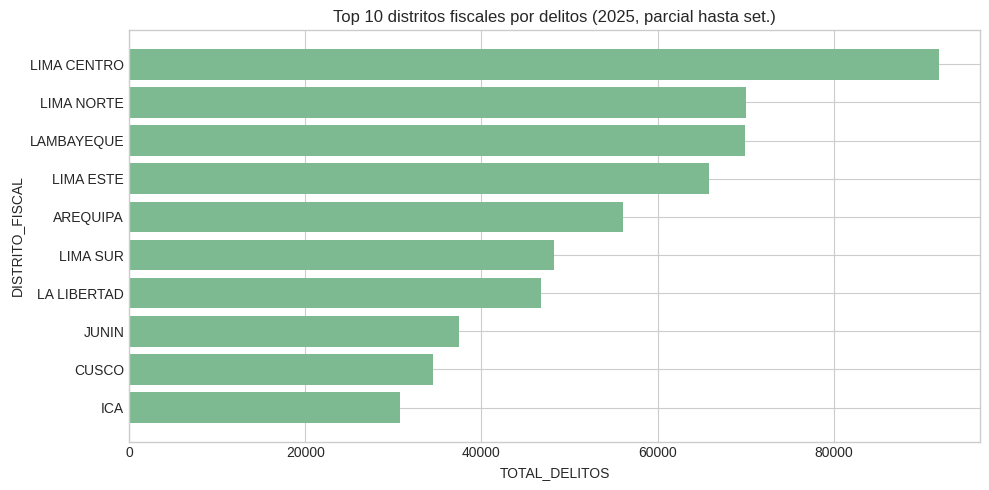

In [45]:
import matplotlib.pyplot as plt

top10 = (df_anual[df_anual['ANIO']==2025]
         .sort_values('TOTAL_DELITOS', ascending=False)
         .head(10))

plt.figure(figsize=(10,5))
plt.barh(top10['DISTRITO_FISCAL'], top10['TOTAL_DELITOS'])
plt.gca().invert_yaxis()
plt.title("Top 10 distritos fiscales por delitos (2025, parcial hasta set.)")
plt.xlabel("TOTAL_DELITOS")
plt.ylabel("DISTRITO_FISCAL")
plt.tight_layout()
plt.show()


In [47]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("delitos_anual_2020_2025.csv", encoding="utf-8")


years_required = [2020, 2021, 2022, 2023, 2024]
grp_counts = df[df['ANIO'].isin(years_required)].groupby('DISTRITO_FISCAL')['ANIO'].nunique()
good_districts = grp_counts[grp_counts == len(years_required)].index.tolist()

df2 = df[df['DISTRITO_FISCAL'].isin(good_districts)].copy()

le = LabelEncoder()
df2['DIST_CODE'] = le.fit_transform(df2['DISTRITO_FISCAL'])

X = df2[['ANIO', 'DIST_CODE']]
y = df2['TOTAL_DELITOS']

print("Shape X:", X.shape, "Shape y:", y.shape)
print("Ejemplo X:\n", X.head())
print("Ejemplo y:\n", y.head())


Shape X: (204, 2) Shape y: (204,)
Ejemplo X:
    ANIO  DIST_CODE
0  2020          0
1  2020          1
2  2020          2
3  2020          3
4  2020          4
Ejemplo y:
 0     8572
1    13762
2    12520
3    33909
4    12964
Name: TOTAL_DELITOS, dtype: int64


In [48]:
!pip -q install skranger
from skranger.ensemble import RangerForestRegressor

RANDOM_STATE = 42


In [54]:
from skranger.ensemble import RangerForestRegressor
from inspect import signature

# Get the parameters of the constructor
params = signature(RangerForestRegressor.__init__).parameters

print("Parameters for RangerForestRegressor.__init__:")
for name, param in params.items():
    print(f"- {name}: {param.kind}")

Parameters for RangerForestRegressor.__init__:
- self: POSITIONAL_OR_KEYWORD
- n_estimators: POSITIONAL_OR_KEYWORD
- verbose: KEYWORD_ONLY
- mtry: KEYWORD_ONLY
- importance: KEYWORD_ONLY
- min_node_size: KEYWORD_ONLY
- max_depth: KEYWORD_ONLY
- replace: KEYWORD_ONLY
- sample_fraction: KEYWORD_ONLY
- keep_inbag: KEYWORD_ONLY
- inbag: KEYWORD_ONLY
- split_rule: KEYWORD_ONLY
- num_random_splits: KEYWORD_ONLY
- alpha: KEYWORD_ONLY
- minprop: KEYWORD_ONLY
- split_select_weights: KEYWORD_ONLY
- always_split_features: KEYWORD_ONLY
- categorical_features: KEYWORD_ONLY
- respect_categorical_features: KEYWORD_ONLY
- scale_permutation_importance: KEYWORD_ONLY
- local_importance: KEYWORD_ONLY
- regularization_factor: KEYWORD_ONLY
- regularization_usedepth: KEYWORD_ONLY
- holdout: KEYWORD_ONLY
- quantiles: KEYWORD_ONLY
- oob_error: KEYWORD_ONLY
- n_jobs: KEYWORD_ONLY
- save_memory: KEYWORD_ONLY
- seed: KEYWORD_ONLY
- enable_tree_details: KEYWORD_ONLY


In [58]:
# === QRF con quantile-forest ===
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from quantile_forest import RandomForestQuantileRegressor

# Asegura tipos numéricos simples
X_np = X.astype("float32").values
y_np = y.astype("float32").values

X_train, X_test, y_train, y_test = train_test_split(
    X_np, y_np, test_size=0.2, shuffle=True, random_state=42
)

qrf = RandomForestQuantileRegressor(
    n_estimators=400,                 # número de árboles
    min_samples_leaf=5,               # tamaño mínimo de hoja
    random_state=42,
    n_jobs=-1
)

qrf.fit(X_train, y_train)

q_lower, q_med, q_upper = 0.10, 0.50, 0.90
pred_q = qrf.predict(X_test, quantiles=[q_lower, q_med, q_upper])
q10, q50, q90 = pred_q[:,0], pred_q[:,1], pred_q[:,2]

mae_mediana = mean_absolute_error(y_test, q50)
print(f"Modelo QRF (quantile-forest) -> MAE mediana (q50): {mae_mediana:,.1f}")

# Ejemplo de tabla comparativa
pred_df = pd.DataFrame({
    "y_real": y_test.ravel(),
    "q10": q10.ravel(),
    "q50": q50.ravel(),
    "q90": q90.ravel()
})
pred_df.head(10)

Modelo QRF (quantile-forest) -> MAE mediana (q50): 9,042.8


,y_real,q10,q50,q90
0,46245.0,46754.0,65967.0,98700.0
1,4650.0,5772.0,12964.0,28782.1
2,42082.0,23207.0,38874.0,45558.0
3,32106.0,5772.0,21687.0,34744.0
4,9384.0,8051.0,12890.0,16934.0
5,20669.0,5897.0,21687.0,34744.0
6,17747.0,10550.0,16338.0,19863.0
7,46097.0,19804.0,28010.0,40354.0
8,12973.0,9041.0,16073.5,19863.0
9,17363.0,5772.0,22088.0,34744.0


In [59]:
import numpy as np
from sklearn.metrics import mean_absolute_error

ok_mono = np.mean((q10 <= q50) & (q50 <= q90))
coverage_10_90 = np.mean((y_test.ravel() >= q10) & (y_test.ravel() <= q90))
mae_mediana = mean_absolute_error(y_test, q50)

print(f"Monotonicidad q10<=q50<=q90: {ok_mono:.3f}")
print(f"Cobertura del intervalo [p10,p90]: {coverage_10_90:.3f}")
print(f"MAE mediana (q50): {mae_mediana:,.1f}")


Monotonicidad q10<=q50<=q90: 1.000
Cobertura del intervalo [p10,p90]: 0.683
MAE mediana (q50): 9,042.8


In [60]:
distritos = df2['DISTRITO_FISCAL'].drop_duplicates().sort_values()
dist_codes = le.transform(distritos)

anio_futuro = 2026
X_future = np.column_stack([
    np.full(len(dist_codes), anio_futuro, dtype=np.float32),
    dist_codes.astype(np.float32)
])

pred_fut = qrf.predict(X_future, quantiles=[0.10, 0.50, 0.90])
f10, f50, f90 = pred_fut[:,0], pred_fut[:,1], pred_fut[:,2]

res_future = pd.DataFrame({
    "DISTRITO_FISCAL": distritos.values,
    "ANIO": anio_futuro,
    "p10": f10,
    "p50": f50,
    "p90": f90
}).sort_values("p50", ascending=False)

res_future.head(12)
res_future.to_csv(f"pred_delitos_QRF_{anio_futuro}.csv", index=False, encoding="utf-8")
print(f"Guardado: pred_delitos_QRF_{anio_futuro}.csv")


Guardado: pred_delitos_QRF_2026.csv


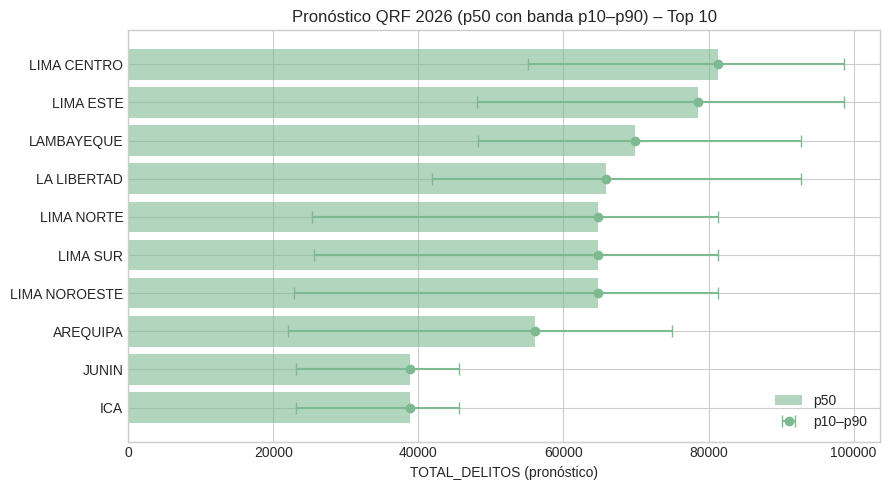

In [61]:
import matplotlib.pyplot as plt

top10 = res_future.head(10).copy()
top10 = top10.iloc[::-1]

plt.figure(figsize=(9,5))
plt.barh(top10["DISTRITO_FISCAL"], top10["p50"], alpha=0.6, label="p50")
err_low  = top10["p50"] - top10["p10"]
err_high = top10["p90"] - top10["p50"]
plt.errorbar(top10["p50"], top10["DISTRITO_FISCAL"], xerr=[err_low, err_high],
             fmt='o', capsize=4, label="p10–p90")
plt.xlabel("TOTAL_DELITOS (pronóstico)")
plt.title(f"Pronóstico QRF {anio_futuro} (p50 con banda p10–p90) – Top 10")
plt.legend()
plt.tight_layout()
plt.show()


In [62]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_pinball_loss

coverage_10_90 = np.mean((y_test >= q10) & (y_test <= q90))
monotone = np.all(q10 <= q50) and np.all(q50 <= q90)

pin_p10 = mean_pinball_loss(y_test, q10, alpha=0.10)
pin_p50 = mean_pinball_loss(y_test, q50, alpha=0.50)
pin_p90 = mean_pinball_loss(y_test, q90, alpha=0.90)
print(f"Monotonicidad p10≤p50≤p90: {monotone}")
print(f"Cobertura [p10,p90]: {coverage_10_90:.3f}")
print(f"Pinball loss p10/p50/p90: {pin_p10:.1f} / {pin_p50:.1f} / {pin_p90:.1f}")


Monotonicidad p10≤p50≤p90: True
Cobertura [p10,p90]: 0.683
Pinball loss p10/p50/p90: 1567.2 / 4521.4 / 2524.7


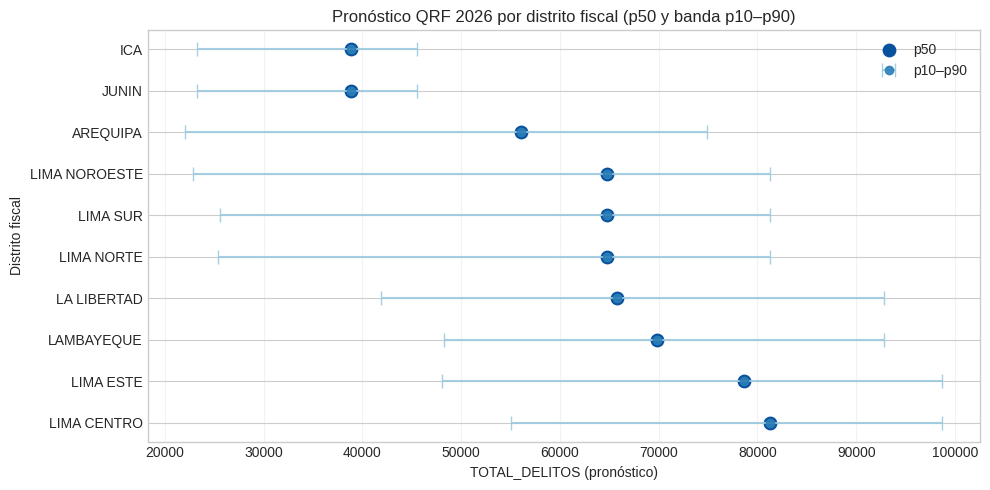

In [64]:
import matplotlib.pyplot as plt

topk = 10
top10 = res_future.sort_values("p50", ascending=False).head(topk)

x = top10["p50"].values
y = top10["DISTRITO_FISCAL"].values
xerr = np.vstack([x - top10["p10"].values, top10["p90"].values - x])

plt.figure(figsize=(10,5))
plt.errorbar(x, y, xerr=xerr, fmt='o', capsize=5, ecolor="#9ecae1", mec="#2c7fb8", mfc="#2c7fb8", alpha=.9, label="p10–p90")
plt.scatter(x, y, s=80, color="#08519c", label="p50")
plt.title(f"Pronóstico QRF {anio_futuro} por distrito fiscal (p50 y banda p10–p90)")
plt.xlabel("TOTAL_DELITOS (pronóstico)")
plt.ylabel("Distrito fiscal")
plt.grid(axis="x", alpha=.25)
plt.legend()
plt.tight_layout()
plt.show()

In [68]:

import pandas as pd
import numpy as np

try:
    df = res_futuro.copy()
except NameError:
    df = pd.read_csv("pred_delitos_QRF_2026.csv", encoding="utf-8")

topk = 10
top10 = df.sort_values("p50", ascending=False).head(topk).reset_index(drop=True)

x = top10["p50"].values
xerr_low  = (top10["p50"] - top10["p10"]).clip(lower=0).values
xerr_high = (top10["p90"] - top10["p50"]).clip(lower=0).values
y = top10["DISTRITO_FISCAL"].values

import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=x, y=y, mode="markers",
    marker=dict(size=12, color="#00E5FF", line=dict(width=1, color="#00FFFF")),
    name="p50",
    hovertemplate="<b>%{y}</b><br>p10=%{customdata[0]:,.0f}<br>p50=%{x:,.0f}<br>p90=%{customdata[1]:,.0f}<extra></extra>",
    customdata=np.c_[top10["p10"].values, top10["p90"].values],
    orientation="h"
))

fig.add_trace(go.Scatter(
    x=x, y=y, mode="markers",
    error_x=dict(type="data", array=xerr_high, arrayminus=xerr_low, color="#FF2DFD", thickness=2, width=0),
    marker=dict(size=0, color="#FF2DFD"),
    name="p10–p90",
    hoverinfo="skip",
    orientation="h"
))

fig.update_layout(
    title=f"Pronóstico QRF 2026 · Top {topk} (p50 y banda p10–p90)",
    xaxis_title="TOTAL_DELITOS (pronóstico)",
    yaxis_title="Distrito fiscal",
    xaxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.08)", zeroline=False),
    yaxis=dict(categoryorder="array", categoryarray=y[::-1], showgrid=False),
    paper_bgcolor="#000000",
    plot_bgcolor="#000000",
    font=dict(color="#E6F3FF"),
    legend=dict(bgcolor="rgba(0,0,0,0.3)", bordercolor="#222", borderwidth=1)
)

fig.add_vline(x=float(np.median(x)), line=dict(color="#39FF14", width=1, dash="dot"), annotation_text="mediana p50", annotation_font_color="#39FF14")

fig.show()


In [80]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from quantile_forest import RandomForestQuantileRegressor

# --- Datos para un distrito (ajusta el nombre si quieres otro) ---
distrito_objetivo = "LIMA CENTRO"
dfg = (df2.loc[df2["DISTRITO_FISCAL"] == distrito_objetivo, ["ANIO","TOTAL_DELITOS"]]
         .dropna()
         .sort_values("ANIO"))

x = dfg["ANIO"].astype("float32").to_numpy()
y = dfg["TOTAL_DELITOS"].astype("float32").to_numpy()
X = x.reshape(-1,1)

# --- Dos modelos: flexible (leaf=10) vs suavizado (leaf=200) ---
qrf_10  = RandomForestQuantileRegressor(n_estimators=1000, min_samples_leaf=10,  random_state=42, n_jobs=-1)
qrf_200 = RandomForestQuantileRegressor(n_estimators=1000, min_samples_leaf=200, random_state=42, n_jobs=-1)
qrf_10.fit(X, y)
qrf_200.fit(X, y)

# Grid continuo de años para dibujar líneas
x_grid = np.linspace(x.min(), x.max(), 300).astype("float32").reshape(-1,1)

q10_10  = qrf_10.predict(x_grid,  quantiles=[0.10]).ravel()
q50_10  = qrf_10.predict(x_grid,  quantiles=[0.50]).ravel()
q90_10  = qrf_10.predict(x_grid,  quantiles=[0.90]).ravel()

q10_200 = qrf_200.predict(x_grid, quantiles=[0.10]).ravel()
q50_200 = qrf_200.predict(x_grid, quantiles=[0.50]).ravel()
q90_200 = qrf_200.predict(x_grid, quantiles=[0.90]).ravel()

# --- Gráfico oscuro con “neón” e interacción ---
fig = go.Figure()
fig.update_layout(template="plotly_dark", title=f"Bandas cuantílicas por año – {distrito_objetivo}",
                  xaxis_title="Año", yaxis_title="TOTAL_DELITOS", hovermode="x")

# Observaciones
fig.add_trace(go.Scatter(x=x, y=y, mode="markers",
                         marker=dict(size=7, color="#9cf6ff", line=dict(color="#00e5ff", width=1)),
                         name="observado", opacity=0.7))

# Ribbon leaf=10
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q90_10, line=dict(color="#ff6bff", width=1),
                         name="q90 (leaf=10)", showlegend=True))
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q10_10, line=dict(color="#ff6bff", width=1),
                         name="q10 (leaf=10)", fill="tonexty",
                         fillcolor="rgba(255,107,255,0.15)", showlegend=True))

# Mediana leaf=10
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q50_10, line=dict(color="#06ffa5", width=2, dash="solid"),
                         name="q50 (leaf=10)"))

# Ribbon leaf=200
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q90_200, line=dict(color="#7d7dff", width=1, dash="dot"),
                         name="q90 (leaf=200)"))
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q10_200, line=dict(color="#7d7dff", width=1, dash="dot"),
                         name="q10 (leaf=200)", fill="tonexty",
                         fillcolor="rgba(125,125,255,0.10)"))

# Mediana leaf=200
fig.add_trace(go.Scatter(x=x_grid.ravel(), y=q50_200, line=dict(color="#00e5ff", width=2, dash="dot"),
                         name="q50 (leaf=200)"))

fig.show()


In [ ]:
Z